# 02 · Activation-pattern contrasts

Each ligand bound by at least one of nodes 0, 1 and 2 carries a three-bit pattern over
[class I, common, class II] (tree `node_2`, `node_1`, `node_3`). The patterns are grouped
into the sets compared here:

- **class1 side**: `100` + `110`, bound by the class I ancestor and not the class II ancestor
- **class2 side**: `001` + `011`, bound by the class II ancestor and not the class I ancestor
- **shared**: `111`, bound by all three
- **common only**: `010`, bound by the common ancestor and by neither class ancestor

`results/group_sizes.csv` gives the four set sizes (Fig. 3c).

In [1]:
import os
import sys
from pathlib import Path

REPO = Path("../..").resolve()
sys.path.append(str(REPO / "Downstream_Analysis/scripts"))
sys.path.append(str(REPO / "scripts"))

from ancestral_sets import ASR_MATRIX, REF_MATRIX, PAIRS, FASTA, FIGURES, TABLES

INPUTS = [ASR_MATRIX, REF_MATRIX, PAIRS, FASTA]
TABLES_WRITTEN = ["group_sizes", "ligand_patterns", "side_descriptors",
                  "side_functional_groups", "pattern_descriptors",
                  "pattern_functional_groups"]
FIGURES_WRITTEN = ["side_descriptors", "side_functional_groups",
                   "pattern_descriptors", "pattern_functional_groups"]

for path in INPUTS:
    print("input  ", os.path.relpath(path, REPO))
print("tables ", os.path.relpath(TABLES, REPO), TABLES_WRITTEN)
print("figures", os.path.relpath(FIGURES, REPO), FIGURES_WRITTEN)

input   Downstream_Analysis/predictions/aggregated/ASR_Predictions/asr_median_probability_wide.csv
input   Downstream_Analysis/predictions/aggregated/Reference_Tree_Predictions/reference_median_probability_wide.csv
input   Model_Inputs/Data_Preparation/processed/m2or_pairs_model.csv
input   Phylogenetic_Analysis/data/ReferenceTree/PF13853.9606_7955_7740_7764_75743_137246.fa
tables  Downstream_Analysis/ancestral_receptors/results ['group_sizes', 'ligand_patterns', 'side_descriptors', 'side_functional_groups', 'pattern_descriptors', 'pattern_functional_groups']
figures Downstream_Analysis/ancestral_receptors/figures ['side_descriptors', 'side_functional_groups', 'pattern_descriptors', 'pattern_functional_groups']


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, kruskal, fisher_exact

from plotting_functions import custom_plots, FIGSIZE
from ancestral_figures import violin
from ancestral_sets import (load_ancestral, functional_groups, descriptors, save_fig,
                            save_table, FG_SMARTS, DESCRIPTORS, PATTERN_ORDER, PATTERN_LABELS)
plt.rcParams.update(custom_plots())

COMMON_COL, CLASS1_COL, CLASS2_COL = "#5F6A72", "#7f1734", "#557c99"

anc = load_ancestral()
chem = descriptors(anc.all_smiles).merge(functional_groups(anc.all_smiles), on="SMILES")
FG_COLS = list(FG_SMARTS)
print(f"ligands active in at least one node: {len(anc.all_smiles)}")

ligands active in at least one node: 39


## Group sizes and presence patterns

Writes `results/group_sizes.csv` (Fig. 3c) and `results/ligand_patterns.csv`, the
pattern of every ligand (Fig. 3b). Patterns with fewer than five ligands are not tested below.

In [3]:
groups = dict(anc.code_sets)
sizes = pd.Series({k: len(v) for k, v in groups.items()})
print(sizes.to_string())
save_table(sizes.rename("n_ligands").reset_index().rename(columns={"index": "group"}),
           "group_sizes")
save_table(anc.pattern_df, "ligand_patterns")

PAT_COL = {"100": CLASS1_COL, "110": "#a85a6b", "111": "#9a8f80",
           "010": COMMON_COL, "011": CLASS2_COL, "001": "#8fb0c4", "101": "#c9c9c4"}
KEEP = [p for p in PATTERN_ORDER if len(anc.pattern_sets[p]) >= 5]
print("patterns tested (n >= 5):", {p: len(anc.pattern_sets[p]) for p in KEEP})

class1_side    19
class2_side     6
shared          2
common_only    12
patterns tested (n >= 5): {'100': 17, '011': 5, '010': 12}


## Class I side against class II side

Descriptor medians with Cliff's delta and a Mann–Whitney test, then functional-group
shares with a Fisher test. Writes `results/side_descriptors.csv` and
`results/side_functional_groups.csv`.

descriptor  class1_side  class2_side  cliffs_delta        p
      logP         2.88         4.46         -0.82 0.003083
      TPSA        37.30        17.07          0.84 0.001889
        MW       223.11       258.40         -0.11 0.726118
       HBD         1.00         0.00          0.74 0.004613
       HBA         1.00         1.00          0.31 0.207175


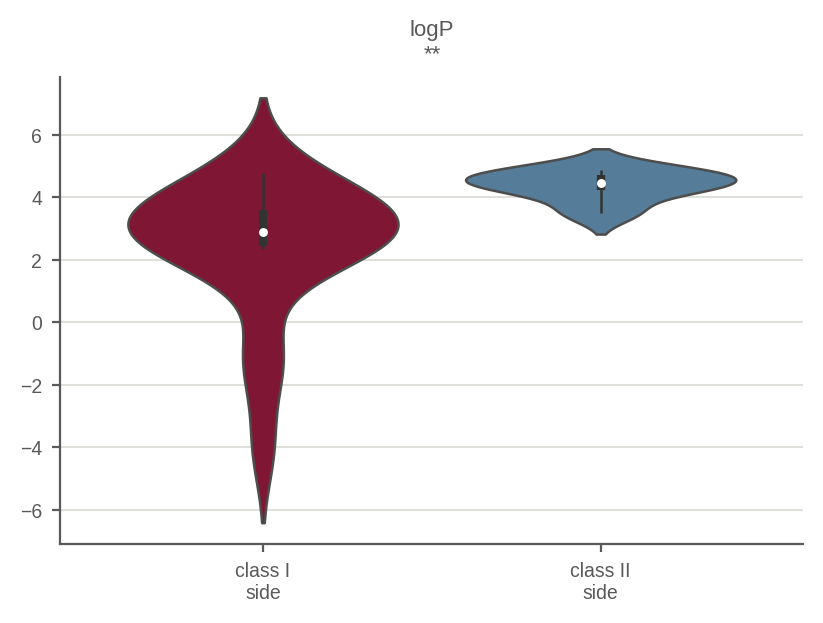

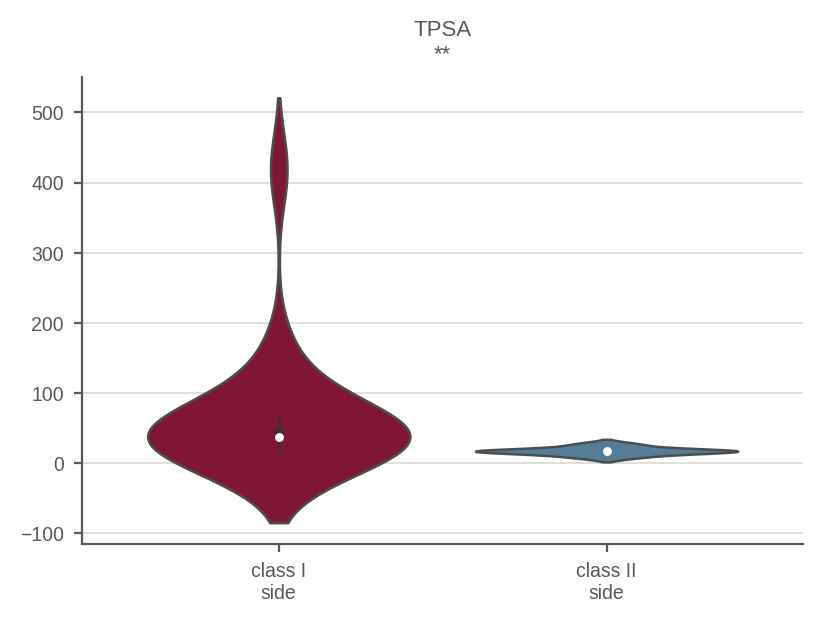

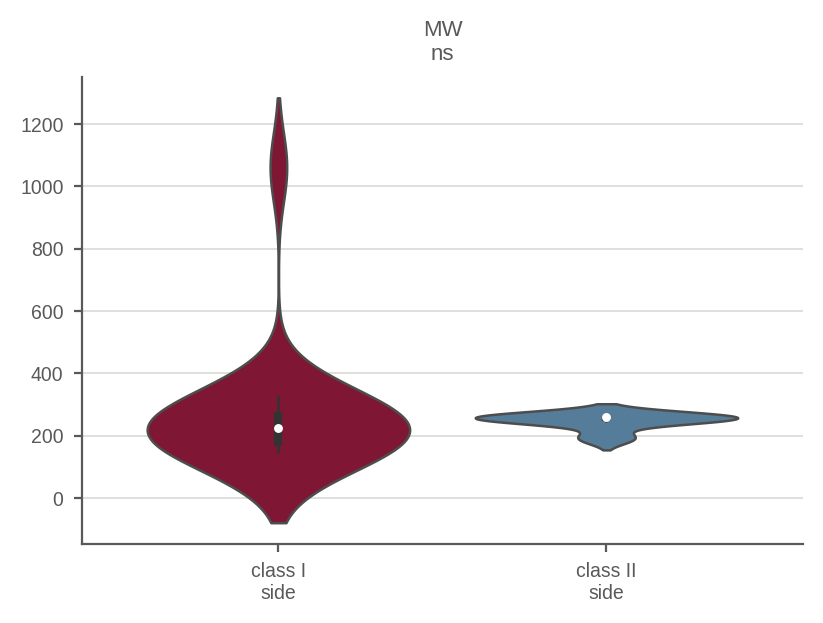

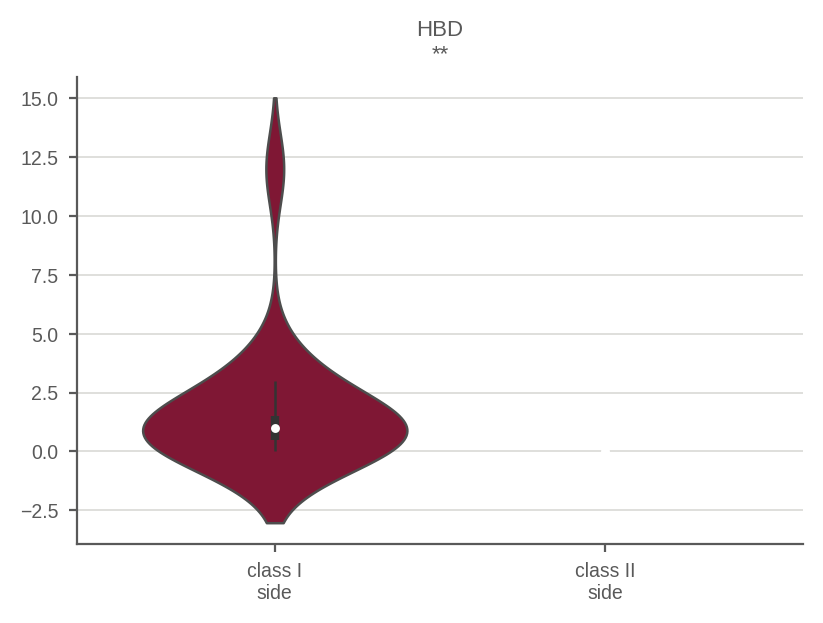

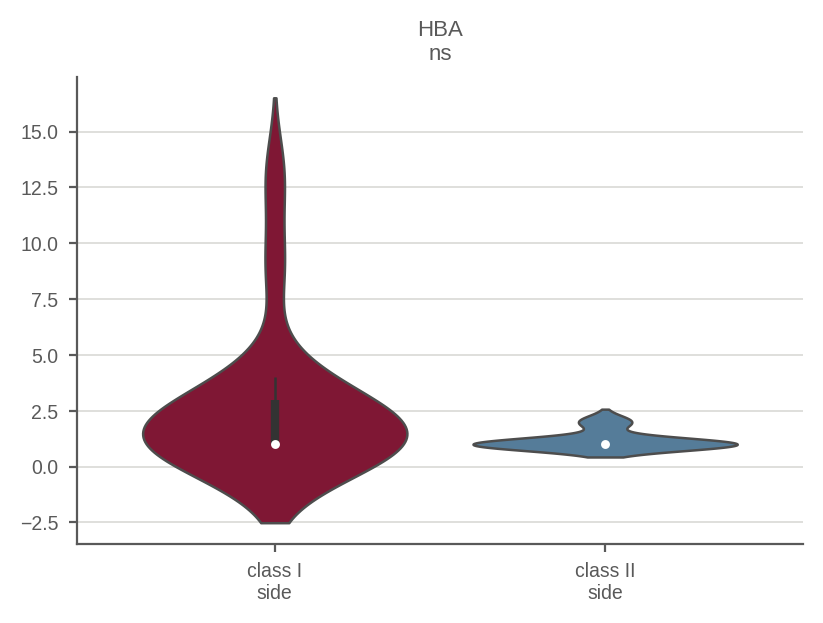

In [4]:
A = chem[chem.SMILES.isin(groups["class1_side"])]
B = chem[chem.SMILES.isin(groups["class2_side"])]


def cliffs(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    return float(np.sign(x[:, None] - y[None, :]).mean())


rows = []
for d in DESCRIPTORS:
    a, b = A[d].dropna(), B[d].dropna()
    rows.append({"descriptor": d, "class1_side": round(a.median(), 2),
                 "class2_side": round(b.median(), 2),
                 "cliffs_delta": round(cliffs(a, b), 2), "p": mannwhitneyu(a, b).pvalue})
res = pd.DataFrame(rows)
print(res.to_string(index=False))
save_table(res, "side_descriptors")

figures, axes = zip(*[plt.subplots(figsize=FIGSIZE, layout="constrained") for _ in range(len(DESCRIPTORS))])
for ax, d in zip(axes, DESCRIPTORS):
    violin(ax, [A[d].dropna().values, B[d].dropna().values], [CLASS1_COL, CLASS2_COL])
    p = float(res.loc[res.descriptor == d, "p"].iloc[0])
    s = "***" if p < 1e-3 else "**" if p < 1e-2 else "*" if p < 0.05 else "ns"
    ax.set_title(f"{d}\n{s}", fontsize=8)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["class I\nside", "class II\nside"], fontsize=7)
    ax.tick_params(labelsize=7)
for figure, d in zip(figures, DESCRIPTORS): save_fig(figure, f"side_descriptors_{d}")
plt.show()

          group  class1_side_%  class2_side_%        p
carboxylic_acid           52.6            0.0 0.050791
  aromatic_ring           36.8           66.7 0.350000
         alkene           31.6           16.7 0.637154
          ether           21.1           16.7 1.000000
        alcohol           15.8            0.0 0.553913
          amine           15.8            0.0 0.553913
         phenol           15.8            0.0 0.553913
       aldehyde           10.5            0.0 1.000000
         ketone           10.5           66.7 0.015133
          amide            5.3            0.0 1.000000
          ester            5.3           16.7 0.430000
        nitrile            0.0            0.0 1.000000


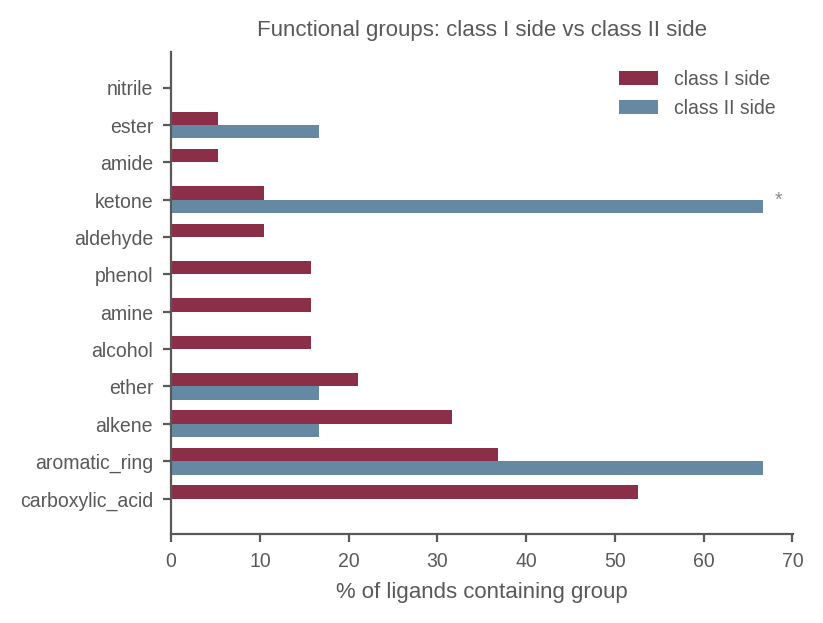

In [5]:
rows = []
for fg in FG_COLS:
    a, b = A[fg], B[fg]
    p = fisher_exact([[int(a.sum()), len(a) - int(a.sum())],
                      [int(b.sum()), len(b) - int(b.sum())]])[1]
    rows.append({"group": fg, "class1_side_%": round(100 * a.mean(), 1),
                 "class2_side_%": round(100 * b.mean(), 1), "p": p})
fg_res = pd.DataFrame(rows).sort_values(["class1_side_%", "group"], ascending=[False, True])
print(fg_res.to_string(index=False))
save_table(fg_res, "side_functional_groups")

fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
y = np.arange(len(fg_res)); w = 0.36
ax.barh(y + w / 2, fg_res["class1_side_%"], w, color=CLASS1_COL, alpha=0.9, label="class I side")
ax.barh(y - w / 2, fg_res["class2_side_%"], w, color=CLASS2_COL, alpha=0.9, label="class II side")
xm = max(fg_res["class1_side_%"].max(), fg_res["class2_side_%"].max())
for yi, p in zip(y, fg_res["p"]):
    if p < 0.05:
        ax.text(xm * 1.02, yi, "*", va="center", color="#8a8a86")
ax.set_yticks(y); ax.set_yticklabels(fg_res["group"])
ax.set_xlabel("% of ligands containing group"); ax.legend()
ax.set_title("Functional groups: class I side vs class II side")
save_fig(fig, "side_functional_groups"); plt.show()

## Chemistry across the patterns

Kruskal–Wallis across the tested patterns for each descriptor, and the functional groups
whose share differs most between patterns. Writes `results/pattern_descriptors.csv` and
`results/pattern_functional_groups.csv`.

descriptor    H        p    100    011    010
      logP 11.1 0.003941   2.88   4.53   2.13
      TPSA 10.8 0.004405  37.30  17.07  26.30
        MW  2.6 0.273130 251.16 258.40 193.24
       HBD 13.3 0.001275   1.00   0.00   0.00
       HBA  5.1 0.077078   1.00   1.00   2.00


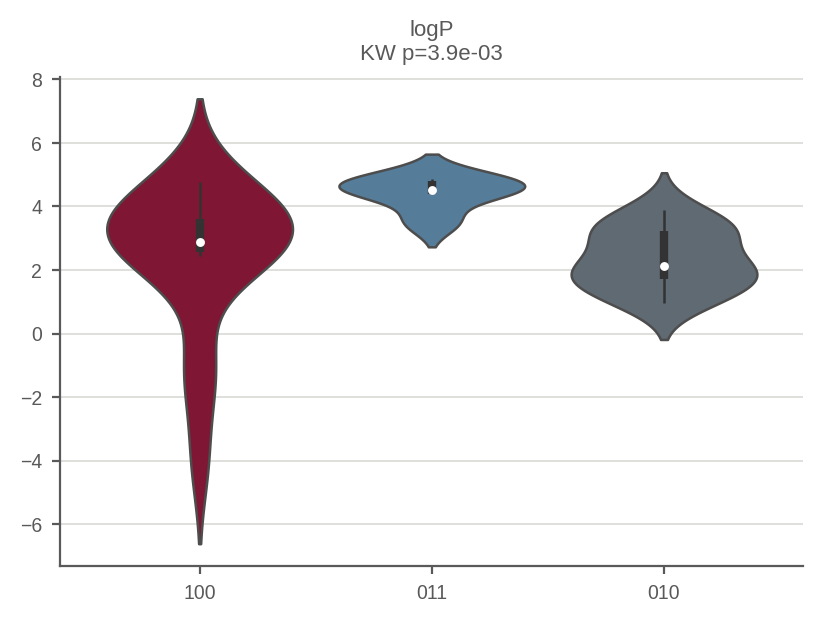

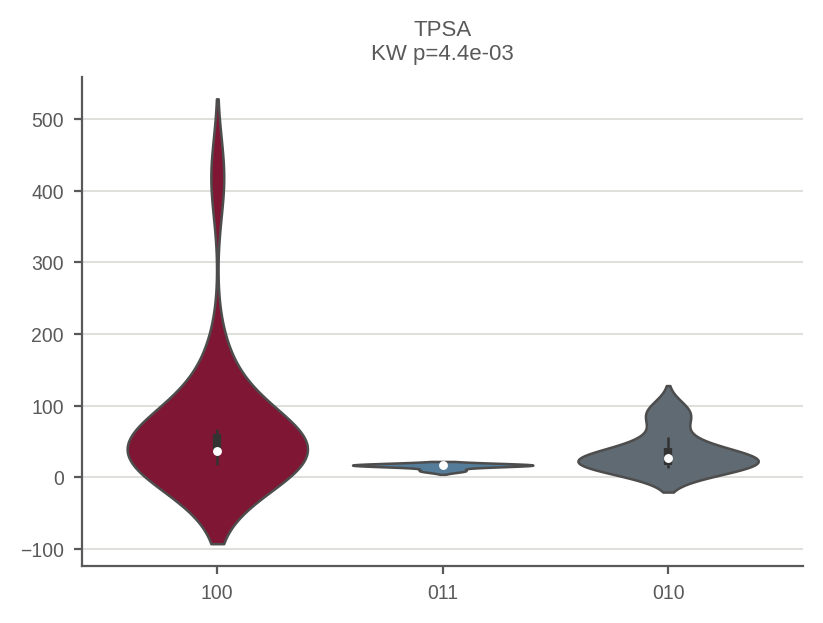

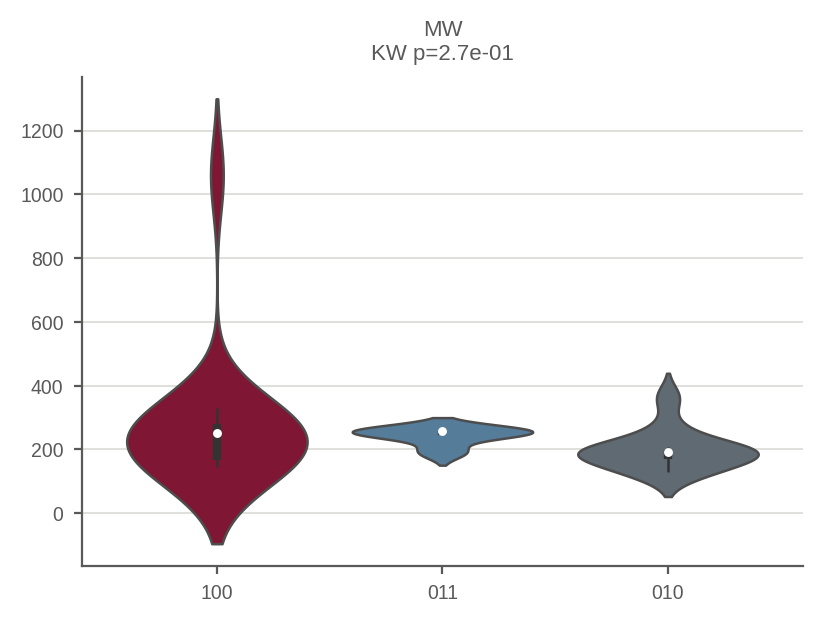

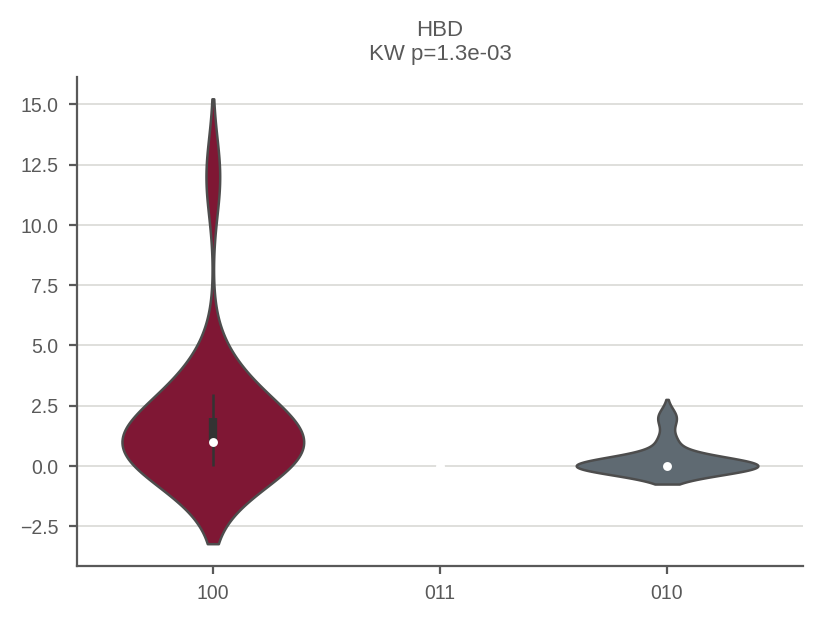

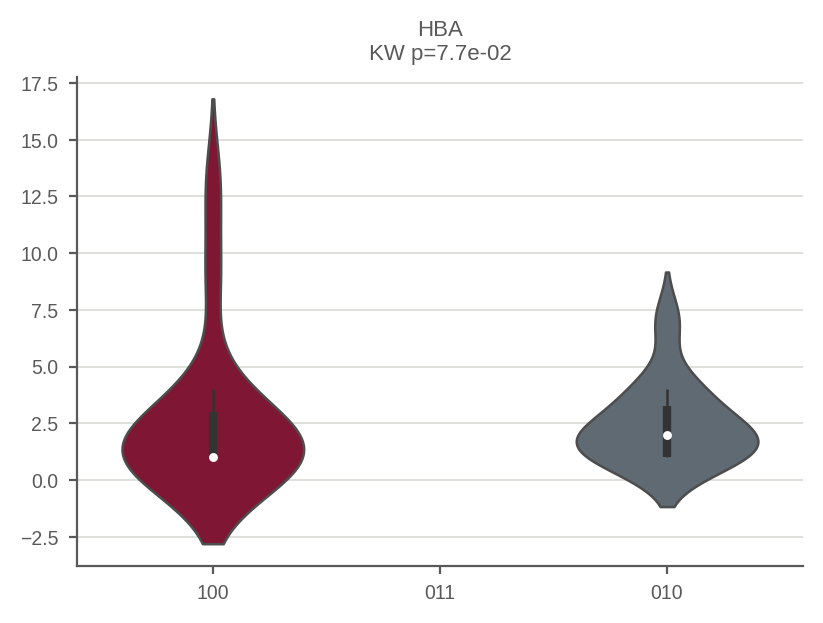

In [6]:
pat_chem = pd.concat([chem[chem.SMILES.isin(anc.pattern_sets[p])].assign(pattern=p)
                      for p in KEEP])

rows = []
for d in DESCRIPTORS:
    data = [pat_chem.loc[pat_chem.pattern == p, d].dropna().values for p in KEEP]
    h, pv = kruskal(*data)
    rows.append({"descriptor": d, "H": round(h, 1), "p": pv,
                 **{p: round(np.median(x), 2) for p, x in zip(KEEP, data)}})
pat_desc = pd.DataFrame(rows)
print(pat_desc.to_string(index=False))
save_table(pat_desc, "pattern_descriptors")

figures, axes = zip(*[plt.subplots(figsize=FIGSIZE, layout="constrained") for _ in range(len(DESCRIPTORS))])
for ax, d in zip(axes, DESCRIPTORS):
    data = [pat_chem.loc[pat_chem.pattern == p, d].dropna().values for p in KEEP]
    violin(ax, data, [PAT_COL[p] for p in KEEP])
    pv = float(pat_desc.loc[pat_desc.descriptor == d, "p"].iloc[0])
    ax.set_title(f"{d}\nKW p={pv:.1e}", fontsize=8)
    ax.set_xticks(range(1, len(KEEP) + 1)); ax.set_xticklabels(KEEP, fontsize=7)
    ax.tick_params(labelsize=7)
for figure, d in zip(figures, DESCRIPTORS): save_fig(figure, f"pattern_descriptors_{d}")
plt.show()

functional_group  100  011  010  spread
          ketone 11.8 80.0 33.3    68.2
 carboxylic_acid 58.8  0.0  0.0    58.8
   aromatic_ring 29.4 80.0 58.3    50.6
          alkene 23.5 20.0 66.7    46.7
           ester  0.0  0.0 33.3    33.3
           ether 11.8 20.0 33.3    21.6
         alcohol 17.6  0.0  8.3    17.6
           amine 17.6  0.0  0.0    17.6
        aldehyde 11.8  0.0  8.3    11.8
          phenol 11.8  0.0  0.0    11.8
           amide  5.9  0.0  8.3     8.3
         nitrile  0.0  0.0  0.0     0.0


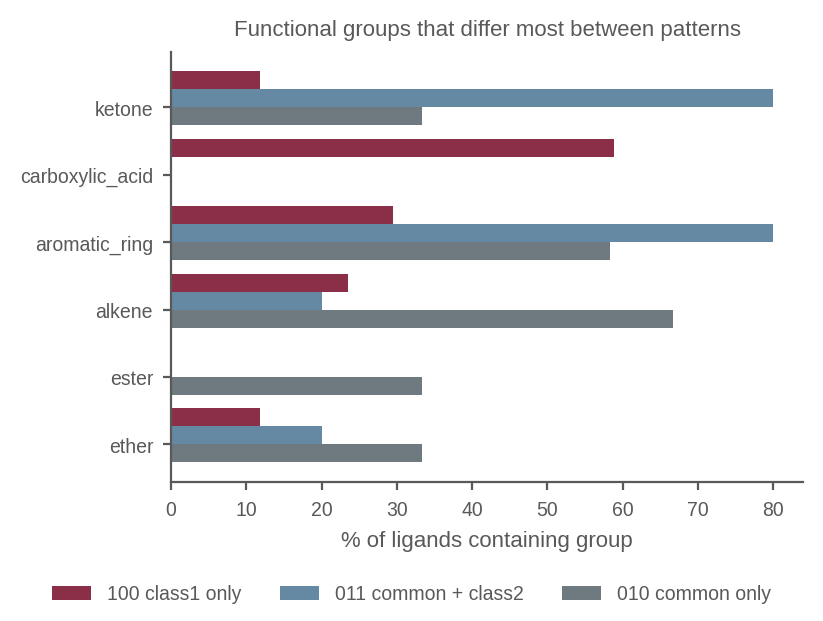

In [7]:
fg_pat = pd.DataFrame({p: chem[chem.SMILES.isin(anc.pattern_sets[p])][FG_COLS].mean() * 100
                       for p in KEEP})
fg_pat["spread"] = fg_pat.max(axis=1) - fg_pat.min(axis=1)
fg_pat = fg_pat.rename_axis("functional_group").reset_index()
fg_pat = fg_pat.sort_values(["spread", "functional_group"], ascending=[False, True])
print(fg_pat.round(1).to_string(index=False))
save_table(fg_pat, "pattern_functional_groups")

show = fg_pat.set_index("functional_group").drop(columns="spread").head(6)
fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
y = np.arange(len(show)); w = 0.8 / len(KEEP)
for i, p in enumerate(KEEP):
    ax.barh(y + (i - len(KEEP) / 2) * w, show[p], w, color=PAT_COL[p], alpha=0.9,
            label=f"{p} {PATTERN_LABELS[p]}")
ax.set_yticks(y); ax.set_yticklabels(show.index); ax.invert_yaxis()
ax.set_xlabel("% of ligands containing group")
fig.legend(loc="outside lower center", ncol=len(KEEP))      # under the axes, off the bars
ax.set_title("Functional groups that differ most between patterns")
save_fig(fig, "pattern_functional_groups"); plt.show()